# Evaluating Hallucination Detection in Arabic–English Code-Switched RAG for UAE Government Services



In [1]:
!pip -q install sentence-transformers rank_bm25 google-genai openai scikit-learn scipy matplotlib seaborn tqdm openpyxl

In [2]:

# ============================== 0. SETUP & CONFIG ==============================
import os, re, json, time, random, hashlib, unicodedata, warnings, math, itertools
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

CFG = dict(
    seed=42,

    # ---- split ----
    dev_frac=0.30,
    eval_on="test",
    sample_n=None,

    # ---- retrieval ----
    embed_model="intfloat/multilingual-e5-base",
    retriever="hybrid",
    top_k=5,
    rrf_k=60,
    w_dense=1.0,
    w_bm25=1.0,
    query_expansion=False,
    max_chars_per_passage=1500,

    # ---- LLMs ----
    gen_provider="gemini",
    gen_model="gemini-flash-lite-latest",

    # Updated Groq judge model
    judge_provider="groq",
    judge_model="openai/gpt-oss-20b",

    gen_rpm=10,
    judge_rpm=20,
    max_retries=6,

    codemix_answer_language="Arabic",
    systems=["naive", "grounded"],
)


DEFAULT_MODELS = {
    "gemini": "gemini-flash-lite-latest",
    "groq": "openai/gpt-oss-20b",
}

random.seed(CFG["seed"])
np.random.seed(CFG["seed"])

# ---- Detect Google Colab ----
try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# ---- Project directory ----
USE_DRIVE = True

if IN_COLAB and USE_DRIVE:
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive")
else:
    BASE = Path(".")

PROJECT_DIR = BASE / "uae-gov-rag-hallucination"

DIRS = {
    n: PROJECT_DIR / p
    for n, p in dict(
        raw="data/raw",
        processed="data/processed",
        cache="outputs/cache",
        tables="outputs/tables",
        figures="outputs/figures",
        audit="outputs/audit",
        gens="outputs/generations",
        src="src",
        reports="reports",
    ).items()
}

for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# ---- API key retrieval ----
def get_secret(name):
    if IN_COLAB:
        try:
            v = userdata.get(name)
            if v:
                return v
        except Exception:
            pass

    return os.environ.get(name)

KEYS = {
    "gemini": get_secret("GEMINI_API_KEY"),
    "groq": get_secret("GROQ_API_KEY"),
}

for k, v in KEYS.items():
    print(f"{k:7s}", "✅ key found" if v else "❌ key missing")

# ---- Resolve providers ----
def resolve_provider(role):
    p = CFG[f"{role}_provider"]

    if KEYS.get(p):
        return

    avail = [x for x in KEYS if KEYS[x]]

    if not avail:
        raise RuntimeError(
            "No API key found. Add GEMINI_API_KEY and/or "
            "GROQ_API_KEY in Colab Secrets."
        )

    print(f"No key for {p} ({role}); falling back to {avail[0]}")

    CFG[f"{role}_provider"] = avail[0]
    CFG[f"{role}_model"] = DEFAULT_MODELS[avail[0]]

for r in ("gen", "judge"):
    resolve_provider(r)

print("GEN  :", CFG["gen_provider"], CFG["gen_model"])
print("JUDGE:", CFG["judge_provider"], CFG["judge_model"])

if (
    CFG["gen_provider"] == CFG["judge_provider"]
    and CFG["gen_model"] == CFG["judge_model"]
):
    print(
        " Generator and judge are the same model → "
        "self-preference bias. Report this as a limitation "
        "or add the second key."
    )

print("Project folder:", PROJECT_DIR)


Mounted at /content/drive
gemini  ✅ key found
groq    ✅ key found
GEN  : gemini gemini-flash-lite-latest
JUDGE: groq openai/gpt-oss-20b
Project folder: /content/drive/MyDrive/uae-gov-rag-hallucination


## 1. LLM wrapper (rate limiting, retries, disk cache, JSON parsing)


In [3]:
# ============================== 1. LLM WRAPPER ==============================
CACHE_PATH = DIRS["cache"] / "llm_cache.jsonl"
_cache = {}
if CACHE_PATH.exists():
    for line in open(CACHE_PATH, encoding="utf-8"):
        try:
            rec = json.loads(line); _cache[rec["k"]] = rec["v"]
        except Exception:
            pass
print(f"Loaded {len(_cache)} cached LLM responses")

class Limiter:
    def __init__(self, rpm): self.gap = 60.0 / max(rpm, 1); self.last = 0.0
    def wait(self):
        dt = time.time() - self.last
        if dt < self.gap: time.sleep(self.gap - dt)
        self.last = time.time()
LIMITERS = {"gen": Limiter(CFG["gen_rpm"]), "judge": Limiter(CFG["judge_rpm"])}
API_STATS = Counter()

class DailyQuotaExceeded(Exception): pass

_clients = {}
def _call_gemini(model, system, user, max_tokens, json_mode):
    from google import genai
    from google.genai import types
    if "gemini" not in _clients: _clients["gemini"] = genai.Client(api_key=KEYS["gemini"])
    cfg = types.GenerateContentConfig(system_instruction=system, temperature=0.0, max_output_tokens=max(max_tokens, 2048),
                                      response_mime_type="application/json" if json_mode else None)
    r = _clients["gemini"].models.generate_content(model=model, contents=user, config=cfg)
    return r.text

def _call_groq(model, system, user, max_tokens, json_mode):
    from openai import OpenAI
    if "groq" not in _clients: _clients["groq"] = OpenAI(api_key=KEYS["groq"], base_url="https://api.groq.com/openai/v1")
    kw = dict(response_format={"type": "json_object"}) if json_mode else {}
    r = _clients["groq"].chat.completions.create(model=model, temperature=0.0, max_tokens=max_tokens,
            messages=[{"role": "system", "content": system}, {"role": "user", "content": user}], **kw)
    return r.choices[0].message.content

def llm(role, system, user, json_mode=True, max_tokens=1024):
    provider, model = CFG[f"{role}_provider"], CFG[f"{role}_model"]
    key = hashlib.sha256(json.dumps([provider, model, system, user, json_mode, max_tokens], ensure_ascii=False).encode()).hexdigest()
    if key in _cache:
        API_STATS["cache_hit"] += 1; return _cache[key]
    for attempt in range(CFG["max_retries"]):
        LIMITERS[role].wait()
        try:
            text = _call_gemini(model, system, user, max_tokens, json_mode) if provider == "gemini" \
                   else _call_groq(model, system, user, max_tokens, json_mode)
            if not text: raise ValueError("empty response")
            _cache[key] = text
            with open(CACHE_PATH, "a", encoding="utf-8") as f: f.write(json.dumps({"k": key, "v": text}, ensure_ascii=False) + "\n")
            API_STATS[f"{role}_calls"] += 1
            return text
        except Exception as e:
            msg = str(e).lower()
            if ("per day" in msg or "perday" in msg or "daily" in msg) and ("quota" in msg or "limit" in msg or "exhaust" in msg):
                raise DailyQuotaExceeded(str(e)[:300])
            if "404" in msg or "not found" in msg or "decommission" in msg:
                raise RuntimeError(f"Model '{model}' not available for {provider}. Edit CFG model id (see model list below). Error: {str(e)[:200]}")
            time.sleep(min(90, 3 * 2 ** attempt) + random.random())
    API_STATS[f"{role}_failed"] += 1
    return None

def parse_json(text):
    if not text: return None
    t = re.sub(r"^```(?:json)?|```$", "", text.strip(), flags=re.M).strip()
    try: return json.loads(t)
    except Exception: pass
    m = re.search(r"\{.*\}", t, flags=re.S)
    if m:
        try: return json.loads(m.group(0))
        except Exception: pass
    return None

def list_models():
    try:
        if KEYS["gemini"]:
            from google import genai
            c = genai.Client(api_key=KEYS["gemini"])
            print("Gemini:", sorted(m.name.replace("models/", "") for m in c.models.list() if "flash" in m.name.lower())[:30])
        if KEYS["groq"]:
            from openai import OpenAI
            c = OpenAI(api_key=KEYS["groq"], base_url="https://api.groq.com/openai/v1")
            print("Groq  :", sorted(m.id for m in c.models.list().data))
    except Exception as e:
        print("Could not list models:", str(e)[:200])

# ---- connectivity test (fail fast) ----
if os.environ.get("SKIP_LLM_TEST") != "1":
    list_models()
    for role in ("gen", "judge"):
        out = parse_json(llm(role, "Reply with JSON only.", 'Return {"ok": true, "ar": "مرحبا"}'))
        print(role, "→", out)
        assert out and out.get("ok") is True, f"{role} LLM test failed – check key / model id"

Loaded 481 cached LLM responses
Gemini: ['gemini-2.5-flash', 'gemini-2.5-flash-image', 'gemini-2.5-flash-lite', 'gemini-2.5-flash-native-audio-latest', 'gemini-2.5-flash-native-audio-preview-09-2025', 'gemini-2.5-flash-native-audio-preview-12-2025', 'gemini-2.5-flash-preview-tts', 'gemini-3-flash-preview', 'gemini-3.1-flash-image', 'gemini-3.1-flash-image-preview', 'gemini-3.1-flash-lite', 'gemini-3.1-flash-lite-image', 'gemini-3.1-flash-lite-preview', 'gemini-3.1-flash-live-preview', 'gemini-3.1-flash-tts-preview', 'gemini-3.5-flash', 'gemini-3.5-flash-lite', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'gemini-3.8-flash-lite-tts', 'gemini-3.8-flash-tts', 'gemini-flash-latest', 'gemini-flash-lite-latest', 'gemini-omni-1.1-flash', 'gemini-omni-flash-preview']
Groq  : ['allam-2-7b', 'canopylabs/orpheus-arabic-saudi', 'canopylabs/orpheus-v1-english', 'meta-llama/llama-prompt-guard-2-22m', 'meta-llama/llama-prompt-guard-2-86m', 'openai/gpt-oss-120b', 'openai/gpt-oss-20b', '

## 2. Load and validate the data


In [4]:
# ============================== 2. DATA ==============================
RAW = DIRS["raw"]
def find_file(cands):
    for c in cands:
        if (RAW / c).exists(): return RAW / c
    return None
DOC_CANDS = ["official_document.csv", "documents.csv", "official_documents.csv"]
doc_path, q_path = find_file(DOC_CANDS), find_file(["final_questions.csv"])
if (doc_path is None or q_path is None) and IN_COLAB:
    from google.colab import files
    print("Upload official_document.csv (or documents.csv) and final_questions.csv")
    for name, data in files.upload().items(): (RAW / name).write_bytes(data)
    doc_path, q_path = find_file(DOC_CANDS), find_file(["final_questions.csv"])
assert doc_path and q_path, f"Put the CSVs in {RAW}"

docs = pd.read_csv(doc_path, encoding="utf-8-sig"); questions = pd.read_csv(q_path, encoding="utf-8-sig")
docs.columns = docs.columns.str.strip(); questions.columns = questions.columns.str.strip()
need_d = ["document_id", "parent_document_id", "source_title", "section_title", "passage_text", "language", "source_url"]
need_q = ["question_id", "question_text", "input_language", "answerability_status", "relevant_document_ids", "expected_answer_en", "expected_answer_ar"]
assert not set(need_d) - set(docs.columns), f"missing doc cols: {set(need_d) - set(docs.columns)}"
assert not set(need_q) - set(questions.columns), f"missing question cols: {set(need_q) - set(questions.columns)}"

for c in ["document_id", "parent_document_id", "source_title", "section_title", "passage_text", "language"]:
    docs[c] = docs[c].astype(str).str.strip()
questions["question_id"] = questions["question_id"].astype(str).str.strip()
questions["question_text"] = questions["question_text"].astype(str).str.strip()
assert docs.document_id.is_unique, "duplicate document_id"
assert questions.question_id.is_unique, "duplicate question_id"
docs = docs[docs.passage_text.str.len() > 0].reset_index(drop=True)

def norm_lang(x):
    s = str(x).strip().lower()
    if any(k in s for k in ["mix", "switch", "code", "hybrid", "bilingual", "both"]): return "Code-mixed"
    if s in ("ar", "arabic") or "arab" in s or "عرب" in s: return "Arabic"
    if s in ("en", "english") or "eng" in s: return "English"
    return "Other"

def norm_answerability(x):
    s = re.sub(r"[\s_\-]+", " ", str(x).strip().lower())
    if re.search(r"\b(un ?answerable|not answerable|no answer|insufficient|not enough|out of scope|cannot be answered|not in (the )?(corpus|documents))\b", s) or s in {"no", "false", "0"}:
        return "unanswerable"
    if "partial" in s: return "partial"
    if "answerable" in s or s in {"yes", "true", "1", "answered"}: return "answerable"
    return "unknown"

docs["lang"] = docs.language.map(norm_lang)
questions["lang"] = questions.input_language.map(norm_lang)
questions["answerability"] = questions.answerability_status.map(norm_answerability)

print("RAW input_language values   :", questions.input_language.value_counts().to_dict())
print("RAW answerability values    :", questions.answerability_status.value_counts().to_dict())
print("→ normalised languages      :", questions.lang.value_counts().to_dict())
print("→ normalised answerability  :", questions.answerability.value_counts().to_dict())
assert (questions.lang != "Other").all(), "Unrecognised input_language value(s) – extend norm_lang()"
assert (questions.answerability != "unknown").all(), "Unrecognised answerability_status value(s) – extend norm_answerability()"
questions["is_unans"] = questions.answerability.eq("unanswerable")   # 'partial' is treated as answerable

DOC_IDS = docs.document_id.tolist(); DOC_POS = {d: i for i, d in enumerate(DOC_IDS)}
PARENT_OF = dict(zip(docs.document_id, docs.parent_document_id))
CHILDREN = docs.groupby("parent_document_id").document_id.apply(list).to_dict()

def parse_ids(x):
    if pd.isna(x): return []
    toks = re.split(r"[,;|\s\[\]'\"]+", str(x))
    return [t for t in toks if t and t.lower() not in ("none", "nan", "null", "na", "n/a", "-")]

def resolve_ids(ids):
    out, unknown = [], []
    for t in ids:
        if t in DOC_POS: out.append(t)
        elif t in CHILDREN: out.extend(CHILDREN[t])   # parent id given → all its passages
        else: unknown.append(t)
    return sorted(set(out)), unknown

parsed = questions.relevant_document_ids.map(parse_ids).map(resolve_ids)
questions["rel_ids"] = parsed.map(lambda t: t[0]); questions["unknown_ids"] = parsed.map(lambda t: t[1])
questions["rel_parents"] = questions.rel_ids.map(lambda L: sorted({PARENT_OF[i] for i in L}))
questions["rel_doc_langs"] = questions.rel_ids.map(lambda L: "+".join(sorted({docs.lang[DOC_POS[i]] for i in L})) if L else "none")

print("\nPassages:", len(docs), "| parents:", docs.parent_document_id.nunique(), "| passage languages:", docs.lang.value_counts().to_dict())
print("Questions:", len(questions)); display(pd.crosstab(questions.lang, questions.answerability, margins=True))
print("Answerable questions with NO resolvable relevant id :", int((~questions.is_unans & (questions.rel_ids.map(len) == 0)).sum()))
print("Unanswerable questions that DO list relevant ids   :", int((questions.is_unans & (questions.rel_ids.map(len) > 0)).sum()))
print("Questions with unresolvable ids                    :", int((questions.unknown_ids.map(len) > 0).sum()))
if (questions.unknown_ids.map(len) > 0).any(): display(questions.loc[questions.unknown_ids.map(len) > 0, ["question_id", "relevant_document_ids", "unknown_ids"]].head())
print("Relevant-doc language by question language:"); display(pd.crosstab(questions.lang[~questions.is_unans], questions.rel_doc_langs[~questions.is_unans]))
display(questions.sample(4, random_state=1)[["question_id", "lang", "answerability", "question_text"]])

RAW input_language values   : {'en': 76, 'ar': 76, 'code_mixed_ar_en': 76}
RAW answerability values    : {'answerable': 114, 'unanswerable': 114}
→ normalised languages      : {'English': 76, 'Arabic': 76, 'Code-mixed': 76}
→ normalised answerability  : {'answerable': 114, 'unanswerable': 114}

Passages: 200 | parents: 100 | passage languages: {'English': 100, 'Arabic': 100}
Questions: 228


answerability,answerable,unanswerable,All
lang,,,
Arabic,38,38,76
Code-mixed,38,38,76
English,38,38,76
All,114,114,228


Answerable questions with NO resolvable relevant id : 0
Unanswerable questions that DO list relevant ids   : 0
Questions with unresolvable ids                    : 0
Relevant-doc language by question language:


rel_doc_langs,Arabic,Arabic+English,English
lang,,,
Arabic,38,0,0
Code-mixed,0,38,0
English,0,0,38


,question_id,lang,answerability,question_text
39,Q0040,English,answerable,Is it possible to register a new business online?
169,Q0170,Arabic,unanswerable,ما قيمة التعويض الدقيقة لكل إصابة عمل؟
93,Q0094,English,answerable,"Is a premarital medical certificate required to get married in the UAE, including for non-Muslims?"
62,Q0063,Code-mixed,answerable,ما الجهة المسؤولة عن licensing charitable organisations؟


## 3. Text normalisation utilities + EDA


['تجديد', 'اقام', 'مقيم', 'وrenew', 'emirate', 'id', '100', 'درهم']


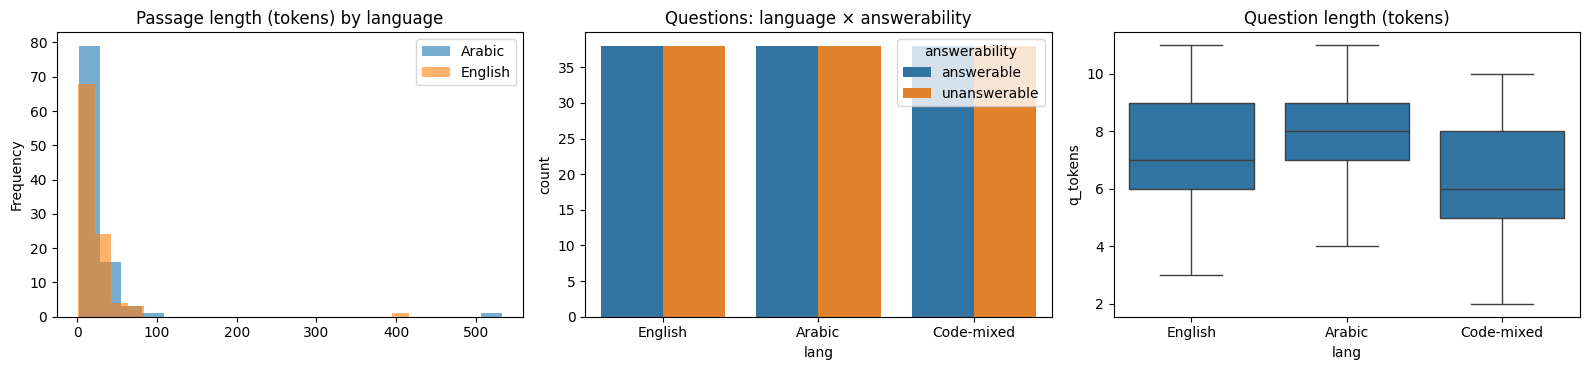

,count,mean,std,min,25%,50%,75%,max
lang,,,,,,,,
Arabic,76.0,1.00,0.01,0.89,1.00,1.00,1.00,1.00
Code-mixed,76.0,0.34,0.14,0.09,0.24,0.33,0.41,0.74
English,76.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [5]:
# ============================== 3. TEXT UTILS ==============================
AR_DIAC = re.compile(r"[\u0610-\u061A\u064B-\u065F\u0670\u06D6-\u06DC\u06DF-\u06E8\u06EA-\u06ED]")
DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹", "01234567890123456789")

def clean_light(t):
    if not isinstance(t, str): return ""
    t = unicodedata.normalize("NFKC", t)
    t = AR_DIAC.sub("", t).replace("\u0640", "").translate(DIGITS)
    return re.sub(r"\s+", " ", t).strip()

def normalize_text(t):
    t = clean_light(t)
    t = re.sub("[إأآٱ]", "ا", t).replace("ى", "ي").replace("ة", "ه").lower()
    return t.replace("،", ",").replace("؟", "?").replace("؛", ";")

STOP_EN = set("a an the of to in on for and or is are was were be been by with at from as that this it its can may must should will shall i you your my we our how what when where which who whom do does did if".split())
STOP_AR = {normalize_text(w) for w in "في من على إلى عن مع هذا هذه ذلك تلك التي الذي الذين أن إن أو ثم قد كان كانت هل ما ماذا كيف متى أين لماذا هو هي هم نحن أنا أنت كل بعد قبل أي لا".split()}
AR_PRE = ("وال", "بال", "كال", "فال", "لل", "ال")
AR_SUF = ("ات", "ان", "ون", "ين", "ها", "ه")
IS_AR = re.compile(r"[\u0600-\u06FF]")

def stem_tok(tok):
    if IS_AR.search(tok):
        for p in AR_PRE:
            if tok.startswith(p) and len(tok) - len(p) >= 3: tok = tok[len(p):]; break
        for s in AR_SUF:
            if tok.endswith(s) and len(tok) - len(s) >= 3: tok = tok[:-len(s)]; break
        return tok
    if tok.endswith("ies") and len(tok) > 4: return tok[:-3] + "y"
    if tok.endswith("s") and not tok.endswith("ss") and len(tok) > 3: return tok[:-1]
    return tok

def tokenize(t):
    toks = re.findall(r"\w+", normalize_text(t))
    return [stem_tok(w) for w in toks if w not in STOP_EN and w not in STOP_AR and (len(w) > 1 or w.isdigit())]

assert normalize_text("الإِقَامَةُ ١٢٣") == "الاقامه 123"
assert tokenize("The visas for residents") == ["visa", "resident"]
print(tokenize("تجديد الإقامة للمقيمين وrenew my Emirates ID ١٠٠ درهم"))

# ---- EDA ----
docs["n_tokens"] = docs.passage_text.map(lambda t: len(tokenize(t)))
questions["q_tokens"] = questions.question_text.map(lambda t: len(tokenize(t)))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
docs.groupby("lang").n_tokens.plot(kind="hist", alpha=.6, bins=20, ax=ax[0], legend=True); ax[0].set_title("Passage length (tokens) by language")
sns.countplot(data=questions, x="lang", hue="answerability", ax=ax[1]); ax[1].set_title("Questions: language × answerability")
sns.boxplot(data=questions, x="lang", y="q_tokens", ax=ax[2]); ax[2].set_title("Question length (tokens)")
plt.tight_layout(); plt.savefig(DIRS["figures"] / "eda.png", dpi=200); plt.show()
# code-mixing intensity: share of Arabic characters in each question
def ar_ratio(t):
    letters = re.findall(r"[A-Za-z\u0600-\u06FF]", t)
    return sum(bool(IS_AR.match(c)) for c in letters) / max(len(letters), 1)
questions["ar_char_ratio"] = questions.question_text.map(ar_ratio)
display(questions.groupby("lang").ar_char_ratio.describe().round(2))

## 4. Dev/test split
Dev questions are used **only** to calibrate the evidence-sufficiency gate threshold. Headline results are on the test split

In [6]:
# ============================== 4. SPLIT ==============================
from sklearn.model_selection import train_test_split
strat = questions.lang + "|" + questions.answerability
try:
    dev_idx, test_idx = train_test_split(questions.index, test_size=1 - CFG["dev_frac"], stratify=strat, random_state=CFG["seed"])
except ValueError:
    dev_idx, test_idx = train_test_split(questions.index, test_size=1 - CFG["dev_frac"], random_state=CFG["seed"])
questions["split"] = "test"; questions.loc[dev_idx, "split"] = "dev"
QPOS = {q: i for i, q in enumerate(questions.question_id)}
display(pd.crosstab([questions.split, questions.lang], questions.answerability))
questions[["question_id", "split"]].to_csv(DIRS["processed"] / "splits.csv", index=False)

eval_df = questions if CFG["eval_on"] == "all" else questions[questions.split == "test"]
if CFG["sample_n"]:
    frac = min(1.0, CFG["sample_n"] / len(eval_df))
    eval_df = pd.concat([g.sample(max(1, round(len(g) * frac)), random_state=CFG["seed"]) for _, g in eval_df.groupby(["lang", "is_unans"])])
eval_df = eval_df.copy()
n_sys = len(CFG["systems"])
print(f"\nLLM evaluation set: {len(eval_df)} questions → approx {len(eval_df) * n_sys} generation + {len(eval_df) * n_sys} judge calls"
      f"{' + ' + str(len(questions)) + ' expansion calls' if CFG['query_expansion'] else ''}")

answerability     answerable  unanswerable
split lang                                
dev   Arabic              12            12
      Code-mixed          11            11
      English             11            11
test  Arabic              26            26
      Code-mixed          27            27
      English             27            27


LLM evaluation set: 160 questions → approx 320 generation + 320 judge calls


## 5. Retrieval: Arabic-aware BM25 + multilingual dense + Reciprocal Rank Fusion
Why hybrid: BM25 is strong on exact terms (fees, service names, numbers) but cannot cross languages; the multilingual-e5 encoder handles Arabic ↔ English and code-mixed queries; RRF fuses both rankings without needing score calibration.

In [7]:

%pip install -q rank-bm25 sentence-transformers


Embedding device: cpu | model: intfloat/multilingual-e5-base


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (8 outputs left out)

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Retrieval over ALL answerable questions (no LLM involved)


hit@1  hit@5  recall@5  parent_hit@5    mrr  ndcg@5
method lang                                                           
bm25   Arabic      0.763  1.000     1.000         1.000  0.865   0.899
       Code-mixed  0.921  0.974     0.724         0.974  0.948   0.742
       English     0.789  0.974     0.974         0.974  0.873   0.899
dense  Arabic      0.974  1.000     1.000         1.000  0.987   0.990
       Code-mixed  0.974  0.974     0.921         0.974  0.974   0.912
       English     1.000  1.000     1.000         1.000  1.000   1.000
hybrid Arabic      0.947  1.000     1.000         1.000  0.974   0.981
       Code-mixed  0.947  0.974     0.882         0.974  0.961   0.860
       English     0.921  0.974     0.974         0.974  0.949   0.954

,hit@1,hit@3,hit@5,hit@10,recall@5,mrr,ndcg@5
method,,,,,,,
bm25,0.825,0.974,0.982,0.982,0.899,0.895,0.847
dense,0.982,0.991,0.991,0.991,0.974,0.987,0.968
hybrid,0.939,0.982,0.982,0.982,0.952,0.961,0.932


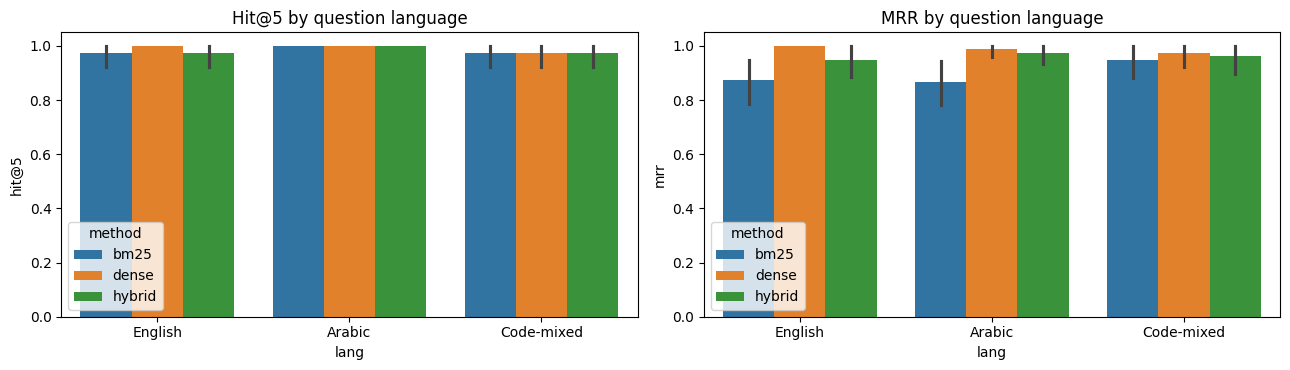

Cross-lingual breakdown (hybrid, Hit@5): question language × language of the relevant passage(s)


hit@5          mrr      
                            mean count   mean count
lang       rel_langs                               
Arabic     Arabic          1.000    38  0.974    38
Code-mixed Arabic+English  0.974    38  0.961    38
English    English         0.974    38  0.949    38

In [8]:
# ============================== 5. RETRIEVAL ==============================
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
try:
    import torch; DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except Exception:
    DEVICE = "cpu"
print("Embedding device:", DEVICE, "| model:", CFG["embed_model"])
embedder = SentenceTransformer(CFG["embed_model"], device=DEVICE)
def embed(texts, prefix):   # e5 models REQUIRE the "query: " / "passage: " prefixes
    return embedder.encode([prefix + clean_light(t) for t in list(texts)], batch_size=32, normalize_embeddings=True, show_progress_bar=False)

docs["dense_text"] = docs.source_title + ". " + docs.section_title + ". " + docs.passage_text
docs["bm25_text"] = docs.source_title + " " + docs.section_title + " " + docs.passage_text
D = embed(docs.dense_text, "passage: ")
bm25 = BM25Okapi([tokenize(t) for t in docs.bm25_text])

# ---- optional LLM query expansion (bilingual rewrite) ----
EXP = {}
if CFG["query_expansion"]:
    EXP_SYS = ('Translate the user question into English and into Modern Standard Arabic. Keep service names, numbers and '
               'official terms. Do NOT answer the question. Return JSON only: {"en": "...", "ar": "..."}')
    for q in tqdm(questions.itertuples(), total=len(questions), desc="query expansion"):
        try: out = parse_json(llm("gen", EXP_SYS, q.question_text, max_tokens=400))
        except DailyQuotaExceeded as e: print("Quota hit during expansion; remaining questions use original text only."); break
        if out: EXP[q.question_id] = (str(out.get("en", "")), str(out.get("ar", "")))

def score_questions(qdf):
    qs = qdf.question_text.tolist(); ids = qdf.question_id.tolist()
    en = [EXP.get(i, ("", ""))[0] or t for i, t in zip(ids, qs)]; ar = [EXP.get(i, ("", ""))[1] or t for i, t in zip(ids, qs)]
    Q = embed(qs, "query: ")
    if CFG["query_expansion"]:
        Q = Q + embed(en, "query: ") + embed(ar, "query: "); Q = Q / np.linalg.norm(Q, axis=1, keepdims=True)
    S_dense = Q @ D.T
    S_bm = np.array([bm25.get_scores(tokenize(f"{t} {e} {a}" if CFG["query_expansion"] else t)) for t, e, a in zip(qs, en, ar)])
    return S_dense, S_bm

def ranks_of(S):
    order = np.argsort(-S, axis=1, kind="stable"); return order, np.argsort(order, axis=1) + 1

S_dense, S_bm = score_questions(questions)       # rows aligned with `questions` (QPOS)
_, rd = ranks_of(S_dense); _, rb = ranks_of(S_bm)
SCORES = {"dense": S_dense, "bm25": S_bm, "hybrid": CFG["w_dense"] / (CFG["rrf_k"] + rd) + CFG["w_bm25"] / (CFG["rrf_k"] + rb)}
ORDER = {m: np.argsort(-S, axis=1, kind="stable") for m, S in SCORES.items()}

def retrieval_table(method, qdf, ks=(1, 3, 5, 10)):
    rows = []
    for q in qdf.itertuples():
        if q.is_unans or not q.rel_ids: continue
        ranked = [DOC_IDS[j] for j in ORDER[method][QPOS[q.question_id]]]; rel = set(q.rel_ids); relp = set(q.rel_parents)
        first = next((r for r, d in enumerate(ranked, 1) if d in rel), None)
        row = dict(method=method, question_id=q.question_id, lang=q.lang, rel_langs=q.rel_doc_langs, mrr=1 / first if first else 0.0)
        for k in ks:
            top = ranked[:k]
            dcg = sum(1 / np.log2(r + 1) for r, d in enumerate(top, 1) if d in rel); idcg = sum(1 / np.log2(r + 1) for r in range(1, min(len(rel), k) + 1))
            row.update({f"hit@{k}": float(any(d in rel for d in top)), f"recall@{k}": len(rel & set(top)) / len(rel),
                        f"parent_hit@{k}": float(any(PARENT_OF[d] in relp for d in top)), f"ndcg@{k}": dcg / idcg})
        rows.append(row)
    return pd.DataFrame(rows)

RET = pd.concat([retrieval_table(m, questions) for m in ["bm25", "dense", "hybrid"]], ignore_index=True)
print("Retrieval over ALL answerable questions (no LLM involved)")
tab = RET.groupby(["method", "lang"])[["hit@1", "hit@5", "recall@5", "parent_hit@5", "mrr", "ndcg@5"]].mean().round(3); display(tab)
display(RET.groupby("method")[["hit@1", "hit@3", "hit@5", "hit@10", "recall@5", "mrr", "ndcg@5"]].mean().round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
sns.barplot(data=RET, x="lang", y="hit@5", hue="method", ax=ax[0], errorbar=("ci", 95)); ax[0].set_title("Hit@5 by question language"); ax[0].set_ylim(0, 1.05)
sns.barplot(data=RET, x="lang", y="mrr", hue="method", ax=ax[1], errorbar=("ci", 95)); ax[1].set_title("MRR by question language"); ax[1].set_ylim(0, 1.05)
plt.tight_layout(); plt.savefig(DIRS["figures"] / "retrieval_by_language.png", dpi=200); plt.show()
print("Cross-lingual breakdown (hybrid, Hit@5): question language × language of the relevant passage(s)")
display(RET[RET.method == "hybrid"].groupby(["lang", "rel_langs"])[["hit@5", "mrr"]].agg(["mean", "count"]).round(3))

## 6. Evidence-sufficiency gate


AUROC of top-1 retrieval score for detecting UNANSWERABLE questions:


,group,n,auroc_dense,auroc_bm25
0,All,228,0.989,0.832
1,Arabic,76,0.981,0.783
2,Code-mixed,76,0.993,0.916
3,English,76,1.000,0.803



Calibrated τ (dev only) = 0.8565 | dev balanced accuracy = 1.000
Gate on TEST (retrieval score only, no LLM): unanswerable recall = 0.975 | answerable wrongly blocked = 0.113


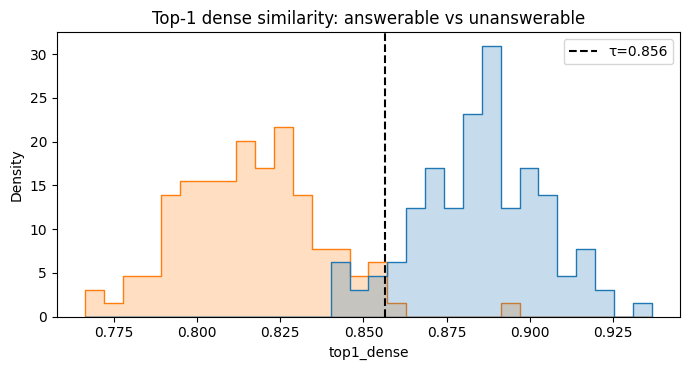

In [9]:
# ============================== 6. GATE ==============================
from sklearn.metrics import roc_auc_score
questions["top1_dense"] = SCORES["dense"].max(1)
questions["top1_bm25"] = SCORES["bm25"].max(1)

def auc(df, col):
    y = df.is_unans.values
    return roc_auc_score(y, -df[col].values) if 0 < y.sum() < len(y) else np.nan
rows = [dict(group="All", n=len(questions), auroc_dense=auc(questions, "top1_dense"), auroc_bm25=auc(questions, "top1_bm25"))]
for l, g in questions.groupby("lang"): rows.append(dict(group=l, n=len(g), auroc_dense=auc(g, "top1_dense"), auroc_bm25=auc(g, "top1_bm25")))
GATE_AUC = pd.DataFrame(rows).round(3); print("AUROC of top-1 retrieval score for detecting UNANSWERABLE questions:"); display(GATE_AUC)

def calibrate_tau(s, y):
    cand = np.unique(s)
    if len(cand) < 2 or y.sum() == 0 or (~y).sum() == 0: return -np.inf, np.nan
    best = (-1, None)
    for t in (cand[:-1] + cand[1:]) / 2:
        pred = s < t; ba = (pred[y].mean() + (~pred[~y]).mean()) / 2
        if ba > best[0]: best = (ba, t)
    return best[1], best[0]

dev = questions[questions.split == "dev"]
TAU, dev_ba = calibrate_tau(dev.top1_dense.values, dev.is_unans.values)
print(f"\nCalibrated τ (dev only) = {TAU:.4f} | dev balanced accuracy = {dev_ba:.3f}")
tst = questions[questions.split == "test"]
pred = tst.top1_dense < TAU
print(f"Gate on TEST (retrieval score only, no LLM): unanswerable recall = {pred[tst.is_unans].mean():.3f} | answerable wrongly blocked = {pred[~tst.is_unans].mean():.3f}")
plt.figure(figsize=(7, 3.8))
sns.histplot(data=questions, x="top1_dense", hue="answerability", bins=30, element="step", stat="density", common_norm=False)
plt.axvline(TAU, color="k", ls="--", label=f"τ={TAU:.3f}"); plt.legend(); plt.title("Top-1 dense similarity: answerable vs unanswerable")
plt.tight_layout(); plt.savefig(DIRS["figures"] / "gate_scores.png", dpi=200); plt.show()

## 7. Generation: two RAG systems
* **naive** – a typical RAG prompt: "answer using the context". No instruction to abstain (this is the hallucination-prone baseline).
* **grounded** – evidence-aware prompt: answer *only* from the passages, cite passage IDs, and return `insufficient_evidence` when the passages do not fully answer the question.
* **+gate** variants (free, no extra calls) – abstain automatically when top-1 retrieval similarity < τ, otherwise use the underlying system's answer.

In [ ]:
# ============================== 7. GENERATION ==============================
PROMPTS = {
"naive": """You are a helpful assistant for UAE government services. Answer the user's question using the context passages provided.
Cite the ids of the passages you used. Output ONLY valid JSON: {"answer": "...", "evidence_ids": ["<passage id>", ...]}""",

"grounded": """You are a careful question-answering assistant for UAE government services.
Use ONLY the numbered evidence passages provided. Never use outside knowledge, even if you know the answer.
RULES
1. If the passages do not contain enough information to fully and correctly answer the question, you MUST return status "insufficient_evidence". Do not guess and do not give a partial answer built from loosely related passages.
2. Otherwise return status "answer": a concise answer (max 4 sentences) that keeps every number, fee, duration, eligibility condition and document name exactly as in the evidence.
3. List the ids of the passages that support the answer in evidence_ids.
4. Write the answer in the language requested in the user message. For "insufficient_evidence", write one short sentence in that language saying the information is not available in the provided sources.
Output ONLY valid JSON: {"status": "answer" | "insufficient_evidence", "answer": "...", "evidence_ids": ["<passage id>", ...], "reason": "<short>"}""",
}

def lang_instruction(lang):
    if lang == "English": return "Answer in English."
    if lang == "Arabic": return "Answer in Modern Standard Arabic."
    return f"The question mixes Arabic and English. Answer in {CFG['codemix_answer_language']}, keeping official English service names where helpful."

_ctx_cache = {}
def build_context(qi, k=None):
    k = k or CFG["top_k"]
    if (qi, k) not in _ctx_cache:
        parts, ids = [], []
        for j in ORDER[CFG["retriever"]][qi, :k]:
            r = docs.iloc[j]; ids.append(r.document_id)
            parts.append(f"[{r.document_id}] ({r.source_title} — {r.section_title}; language: {r.lang})\n{r.passage_text[:CFG['max_chars_per_passage']]}")
        _ctx_cache[(qi, k)] = ("\n\n".join(parts), ids)
    return _ctx_cache[(qi, k)]

def run_generation(system_name):
    rows = []
    for q in tqdm(eval_df.itertuples(), total=len(eval_df), desc=f"generate:{system_name}"):
        qi = QPOS[q.question_id]; ctx, ids = build_context(qi)
        user = f"Question language: {q.lang}\n{lang_instruction(q.lang)}\n\nQuestion: {q.question_text}\n\nEvidence passages:\n{ctx}\n\nReturn JSON only."
        try: raw = llm("gen", PROMPTS[system_name], user, json_mode=True, max_tokens=1024)
        except DailyQuotaExceeded as e:
            print(f"\n⛔ Daily quota reached ({str(e)[:120]}). Re-run this cell later – cached results are reused."); break
        p = parse_json(raw) or {}
        ans = p.get("answer") if p else None
        rows.append(dict(question_id=q.question_id, system=system_name, ok=raw is not None, parse_ok=bool(p),
                         answer=str(ans) if ans is not None else (raw or ""), status=p.get("status", ""), evidence_ids=p.get("evidence_ids", []) if isinstance(p.get("evidence_ids", []), list) else []))
    return pd.DataFrame(rows)

GEN = {s: run_generation(s) for s in CFG["systems"]}
for s, g in GEN.items(): print(s, "| generated:", len(g), "| failed:", int((~g.ok).sum()) if len(g) else 0, "| JSON parse failures:", int((~g.parse_ok).sum()) if len(g) else 0)
print(dict(API_STATS))

generate:naive:   0%|          | 0/160 [00:00<?, ?it/s]

generate:grounded:   0%|          | 0/160 [00:00<?, ?it/s]

naive | generated: 160 | failed: 0 | JSON parse failures: 0
grounded | generated: 160 | failed: 0 | JSON parse failures: 0
{'cache_hit': 1, 'judge_calls': 1, 'gen_calls': 320}


In [ ]:

# SAVE COMPLETED GENERATION RESULTS — NO API CALLS
import json

for system_name, df in GEN.items():
    save_path = DIRS["gens"] / f"generation_{system_name}.csv"
    saved = df.copy()

    # Store evidence IDs safely in the CSV
    saved["evidence_ids"] = saved["evidence_ids"].apply(
        lambda x: json.dumps(x if isinstance(x, list) else [], ensure_ascii=False)
    )

    saved.to_csv(save_path, index=False, encoding="utf-8-sig")
    print(f"Saved {len(saved)} rows: {save_path}")

print("Generation results saved.")


Saved 160 rows: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/generations/generation_naive.csv
Saved 160 rows: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/generations/generation_grounded.csv
Generation results saved.


verify

In [ ]:

from pathlib import Path
import pandas as pd

gen_dir = Path(
    "/content/drive/MyDrive/uae-gov-rag-hallucination/outputs/generations"
)

for name in ["naive", "grounded"]:
    path = gen_dir / f"generation_{name}.csv"
    df = pd.read_csv(path, encoding="utf-8-sig")

    print(f"\n{name.upper()}")
    print("File exists:", path.exists())
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("Unique question IDs:", df["question_id"].nunique())
    print("Saved to:", path)



NAIVE
File exists: True
Rows: 160
Columns: ['question_id', 'system', 'ok', 'parse_ok', 'answer', 'status', 'evidence_ids']
Unique question IDs: 160
Saved to: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/generations/generation_naive.csv

GROUNDED
File exists: True
Rows: 160
Columns: ['question_id', 'system', 'ok', 'parse_ok', 'answer', 'status', 'evidence_ids']
Unique question IDs: 160
Saved to: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/generations/generation_grounded.csv


## 8. Hallucination detection
Two layers:
1. **LLM judge** (a *different* model family from the generator) returns structured labels per answer: `abstained`, `faithfulness` vs. the retrieved passages, `correctness` vs. the reference answers (EN + AR).
2. **Deterministic checks**: citation validity, number-grounding (numbers in the answer that never appear in the evidence), and embedding similarity to the reference answer.

**Definitions used in the results**
* *Hallucination* = the system answered (did not abstain) **and** (the question is unanswerable **or** the answer is not fully supported by the retrieved evidence).
* *Good response* = correct abstention on an unanswerable question, **or** a correct-or-partly-correct, fully-supported answer on an answerable one.

In [12]:

import json
import pandas as pd

GEN = {}

for name in CFG["systems"]:
    path = DIRS["gens"] / f"generation_{name}.csv"

    if not path.exists():
        raise FileNotFoundError(f"Saved generation file missing: {path}")

    g = pd.read_csv(path, encoding="utf-8-sig")

    g["question_id"] = g["question_id"].astype(str)
    g["ok"] = g["ok"].astype(str).str.lower().eq("true")
    g["parse_ok"] = g["parse_ok"].astype(str).str.lower().eq("true")

    def restore_evidence_ids(x):
        if isinstance(x, list):
            return x
        if pd.isna(x) or not str(x).strip():
            return []
        try:
            value = json.loads(x)
            return value if isinstance(value, list) else []
        except (json.JSONDecodeError, TypeError):
            return []

    g["evidence_ids"] = g["evidence_ids"].apply(restore_evidence_ids)
    GEN[name] = g

    print(
        name,
        "| rows:", len(g),
        "| successful:", int((g["ok"] & g["parse_ok"]).sum())
    )

print("GEN restored successfully.")


naive | rows: 160 | successful: 160
grounded | rows: 160 | successful: 160
GEN restored successfully.


In [14]:

for name in ["build_context", "QPOS", "DOC_POS", "docs", "ORDER", "CFG"]:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")


build_context: MISSING
QPOS: available
DOC_POS: available
docs: available
ORDER: available
CFG: available


In [15]:

# Search notebook code cells for the original build_context definition
import json
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/uae-gov-rag-hallucination/"
    "uae_gov_rag_hallucination.ipynb"
)

print("Notebook exists:", notebook_path.exists())


Notebook exists: False


In [10]:

# RESTORE ORIGINAL build_context() — NO API CALLS
_ctx_cache = {}

def build_context(qi, k=None):
    k = k or CFG["top_k"]

    if (qi, k) not in _ctx_cache:
        parts, ids = [], []

        for j in ORDER[CFG["retriever"]][qi, :k]:
            r = docs.iloc[j]
            ids.append(r.document_id)

            parts.append(
                f"[{r.document_id}] "
                f"({r.source_title} — {r.section_title}; "
                f"language: {r.lang})\n"
                f"{r.passage_text[:CFG['max_chars_per_passage']]}"
            )

        _ctx_cache[(qi, k)] = ("\n\n".join(parts), ids)

    return _ctx_cache[(qi, k)]

print("Original build_context() restored successfully.")


Original build_context() restored successfully.


In [17]:

test_qid = eval_df.iloc[0]["question_id"]
test_qi = QPOS[test_qid]

context, retrieved_ids = build_context(test_qi)

print("Test question ID:", test_qid)
print("Retrieved passages:", len(retrieved_ids))
print("Context preview:", context[:500])

assert isinstance(context, str) and len(context) > 0
assert len(retrieved_ids) > 0

print("Context test passed.")


Test question ID: Q0001
Retrieved passages: 5
Context preview: [UAE001_EN] (Health and Fitness — Where can I find a list of healthcare centres and facilities?; language: English)
You can look for medical facilities on the websites of:

1.Emirates Health Services
2.Abu Dhabi Government
3.Seha
4.Government of Ajman
5.Dubai Health Experience.

[UAE003_EN] (Health and Fitness — What do I need to access UAE healthcare facilities services?; language: English)
You need to present your Emirates ID or passport.

[UAE075_EN] (People of determination (special needs or
Context test passed.


In [18]:
# ============================== 8. LOCAL JUDGE (no API calls, CPU) ==============================
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
NLI_NAME = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"
tok = AutoTokenizer.from_pretrained(NLI_NAME); nli = AutoModelForSequenceClassification.from_pretrained(NLI_NAME).eval()
ENT = [i for i, l in nli.config.id2label.items() if l.lower().startswith("entail")][0]
torch.set_num_threads(max(1, os.cpu_count() or 1))

@torch.no_grad()
def entail(premises, hyps, bs=16):
    out = []
    for i in range(0, len(premises), bs):
        enc = tok(premises[i:i+bs], hyps[i:i+bs], truncation="only_first", max_length=384, padding=True, return_tensors="pt")
        out += torch.softmax(nli(**enc).logits, -1)[:, ENT].tolist()
    return out

REFUSAL = re.compile(r"(not available|no information|insufficient|cannot (be )?(answer|determine)|not (specified|mentioned|provided)|"
                     r"لا تتوفر|غير متوفر|لا توجد معلومات|لا تتضمن|لا يمكن|غير متاح|لا تحتوي)", re.I)
T_SUPPORT, T_CORRECT, T_SIM_PARTIAL = 0.50, 0.50, 0.80      # tune these using the human audit sheet (Section 10b)

def sentences(t): return [s.strip() for s in re.split(r"(?<=[.!?؟])\s+|\n", str(t)) if len(s.strip()) > 3]

def local_judge(q, answer, status):
    ab = (status == "insufficient_evidence") or bool(REFUSAL.search(str(answer))) or len(str(answer).strip()) < 3
    if ab: return dict(judge_ok=True, abstained=True, faith="not_applicable", corr_label="not_applicable", unsupported_claims=[], judge_expl="local: abstained")
    _, ids = build_context(QPOS[q.question_id]); psg = [docs.passage_text[DOC_POS[i]][:1200] for i in ids]
    sents = sentences(answer) or [str(answer)]
    pairs = [(p, s) for s in sents for p in psg]
    probs = np.array(entail([p for p, _ in pairs], [s for _, s in pairs])).reshape(len(sents), len(psg)).max(1)
    sup = probs >= T_SUPPORT
    faith = "fully_supported" if sup.all() else ("partially_supported" if sup.any() else "unsupported")
    if q.is_unans:
        corr = "incorrect"
    else:
        refs = [r for r in (q.expected_answer_en, q.expected_answer_ar) if isinstance(r, str) and r.strip()]
        e = max(entail([str(answer)] * len(refs), refs)) if refs else 0.0
        a = embed([answer], "query: ")[0]; sim = max(float(a @ embed([r], "query: ")[0]) for r in refs) if refs else 0.0
        corr = "correct" if e >= T_CORRECT else ("partially_correct" if sim >= T_SIM_PARTIAL else "incorrect")
    return dict(judge_ok=True, abstained=False, faith=faith, corr_label=corr,
                unsupported_claims=[s for s, ok in zip(sents, sup) if not ok], judge_expl=f"local NLI min-support={probs.min():.2f}")

def run_judge(system_name):
    g = GEN[system_name]; g = g[g.ok]; qmap = eval_df.set_index("question_id", drop=False); rows = []
    for r in tqdm(g.itertuples(), total=len(g), desc=f"local-judge:{system_name}"):
        q = next(qmap.loc[[r.question_id]].itertuples())
        rows.append(dict(question_id=r.question_id, **local_judge(q, r.answer, r.status)))
    return pd.DataFrame(rows)

JUDGE = {s: run_judge(s) for s in CFG["systems"] if len(GEN[s])}
for s, j in JUDGE.items(): print(s, "| judged:", len(j))

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

local-judge:naive:   0%|          | 0/160 [00:00<?, ?it/s]

local-judge:grounded:   0%|          | 0/160 [00:00<?, ?it/s]

naive | judged: 160
grounded | judged: 160


In [19]:
from pathlib import Path

# Save local judge results to Google Drive
judge_dir = Path(
    "/content/drive/MyDrive/uae-gov-rag-hallucination/outputs/judgments"
)
judge_dir.mkdir(parents=True, exist_ok=True)

for system_name, result in JUDGE.items():
    output_path = judge_dir / f"judgment_{system_name}.csv"
    result.to_csv(output_path, index=False, encoding="utf-8-sig")

    print(f"Saved: {output_path.name} | Rows: {len(result)}")

print("Local Judge results saved successfully.")

Saved: judgment_naive.csv | Rows: 160
Saved: judgment_grounded.csv | Rows: 160
Local Judge results saved successfully.


In [20]:
# ============================== 8b. ASSEMBLE + DETERMINISTIC CHECKS ==============================
META = ["question_id", "lang", "answerability", "is_unans", "split", "question_text", "expected_answer_en", "expected_answer_ar", "rel_ids", "top1_dense"]

def numbers(t): return {n.replace(",", "").rstrip(".") for n in re.findall(r"\d+(?:[.,]\d+)*", clean_light(t))}

def assemble(s):
    df = GEN[s].merge(JUDGE[s], on="question_id").merge(questions[META], on="question_id")
    df = df[df.judge_ok].copy()
    ctxs = [build_context(QPOS[q]) for q in df.question_id]
    df["retrieved_ids"] = [c[1] for c in ctxs]
    def num_unsup(a, c):
        na = numbers(a); return len(na - numbers(c)) / len(na) if na else np.nan
    df["num_unsupported"] = [np.nan if ab else num_unsup(a, c[0]) for a, c, ab in zip(df.answer, ctxs, df.abstained)]
    df["cite_valid"] = [np.nan if (ab or not e) else float(all(x in r for x in e)) for e, r, ab in zip(df.evidence_ids, df.retrieved_ids, df.abstained)]
    df["cite_hit_relevant"] = [np.nan if (ab or u or not e) else float(any(x in set(rel) for x in e)) for e, rel, ab, u in zip(df.evidence_ids, df.rel_ids, df.abstained, df.is_unans)]
    A = embed(df.answer, "query: "); REn = embed(df.expected_answer_en.fillna(""), "query: "); RAr = embed(df.expected_answer_ar.fillna(""), "query: ")
    sim = np.maximum((A * REn).sum(1), (A * RAr).sum(1))
    df["ref_sim"] = np.where(df.abstained | df.is_unans, np.nan, sim)
    df["gated"] = False
    return df

def add_outcomes(df):
    df = df.copy(); ans = ~df.abstained; unfaith = df.faith.isin(["unsupported", "partially_supported"])
    df["halluc"] = ans & (df.is_unans | unfaith)
    df["unfaithful"] = ans & unfaith
    df["corr_strict"] = (~df.is_unans) & ans & df.corr_label.eq("correct")
    df["corr_lenient"] = (~df.is_unans) & ans & df.corr_label.isin(["correct", "partially_correct"])
    df["good"] = (df.is_unans & df.abstained) | ((~df.is_unans) & ans & df.corr_label.isin(["correct", "partially_correct"]) & df.faith.eq("fully_supported"))
    return df

def gate_variant(df, base):
    g = df.copy(); mask = g.top1_dense < TAU
    g.loc[mask, "abstained"] = True; g.loc[mask, ["faith", "corr_label"]] = "not_applicable"
    g.loc[mask, ["num_unsupported", "cite_valid", "cite_hit_relevant", "ref_sim"]] = np.nan
    g.loc[mask, "answer"] = "[gate: insufficient retrieval evidence]"; g["gated"] = mask; g["system"] = base + "+gate"
    return g

RES = {}
for s in JUDGE:
    if not len(JUDGE[s]): continue
    base = assemble(s); RES[s] = add_outcomes(base); RES[s + "+gate"] = add_outcomes(gate_variant(base, s))
ALL = pd.concat(RES.values(), ignore_index=True)
ALL["system"] = pd.Categorical(ALL.system, [k for k in RES], ordered=True)
print("Rows per system:", ALL.system.value_counts().to_dict())
ALL.drop(columns=["retrieved_ids"]).to_csv(DIRS["gens"] / "all_results.csv", index=False, encoding="utf-8-sig")

Rows per system: {'naive': 160, 'naive+gate': 160, 'grounded': 160, 'grounded+gate': 160}


In [21]:
from pathlib import Path
import pandas as pd

output_path = Path(DIRS["gens"]) / "all_results.csv"

if output_path.exists():
    saved = pd.read_csv(output_path)
    print("File exists:", output_path)
    print("Total rows:", len(saved))
    print("\nRows per system:")
    print(saved["system"].value_counts().to_string())
else:
    print("File not found. Save ALL again.")

File exists: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/generations/all_results.csv
Total rows: 640

Rows per system:
system
naive            160
naive+gate       160
grounded         160
grounded+gate    160


In [30]:
# ============================== 8c. ROUGE (supplementary, language-matched reference) ==============================
def rtoks(t): return [stem_tok(w) for w in re.findall(r"\w+", normalize_text(t))]

def f1(overlap, n_ref, n_hyp):
    if overlap == 0 or n_ref == 0 or n_hyp == 0: return 0.0
    p, r = overlap / n_hyp, overlap / n_ref
    return 2 * p * r / (p + r)

def rouge_n(ref, hyp, n):
    grams = lambda t: Counter(zip(*[t[i:] for i in range(n)]))
    rg, hg = grams(ref), grams(hyp)
    return f1(sum((rg & hg).values()), sum(rg.values()), sum(hg.values()))

def rouge_l(ref, hyp):
    if not ref or not hyp: return 0.0
    prev = [0] * (len(hyp) + 1)
    for a in ref:
        cur = [0]
        for j, b in enumerate(hyp, 1):
            cur.append(prev[j - 1] + 1 if a == b else max(prev[j], cur[-1]))
        prev = cur
    return f1(prev[-1], len(ref), len(hyp))

def ref_for(row):   # reference in the language the answer was requested in
    use_en = row.lang == "English" or (row.lang == "Code-mixed" and CFG["codemix_answer_language"] == "English")
    return row.expected_answer_en if use_en else row.expected_answer_ar

def add_rouge(df):
    df = df.copy(); r1, r2, rl = [], [], []
    for row in df.itertuples():
        if row.abstained or row.is_unans or not isinstance(ref_for(row), str):
            r1.append(np.nan); r2.append(np.nan); rl.append(np.nan); continue
        ref, hyp = rtoks(ref_for(row)), rtoks(row.answer)
        r1.append(rouge_n(ref, hyp, 1)); r2.append(rouge_n(ref, hyp, 2)); rl.append(rouge_l(ref, hyp))
    df["rouge1"], df["rouge2"], df["rougeL"] = r1, r2, rl
    return df

RES = {k: add_rouge(v) for k, v in RES.items()}
ALL = pd.concat(RES.values(), ignore_index=True)
ALL["system"] = pd.Categorical(ALL.system, list(RES), ordered=True)
print("ROUGE F1 on answered, answerable questions (reference in the answer's language):")
display(ALL.groupby(["system", "lang"], observed=True)[["rouge1", "rouge2", "rougeL"]].agg(["mean", "count"]).round(3))

ROUGE F1 on answered, answerable questions (reference in the answer's language):


rouge1       rouge2       rougeL      
                           mean count   mean count   mean count
system        lang                                             
naive         Arabic      0.720    24  0.611    24  0.664    24
              Code-mixed  0.628    26  0.498    26  0.585    26
              English     0.691    27  0.538    27  0.644    27
naive+gate    Arabic      0.716    22  0.607    22  0.657    22
              Code-mixed  0.643    19  0.518    19  0.620    19
              English     0.691    27  0.538    27  0.644    27
grounded      Arabic      0.804    22  0.740    22  0.789    22
              Code-mixed  0.731    25  0.647    25  0.717    25
              English     0.849    25  0.787    25  0.818    25
grounded+gate Arabic      0.801    20  0.736    20  0.786    20
              Code-mixed  0.756    18  0.684    18  0.748    18
              English     0.849    25  0.787    25  0.818    25

In [33]:

# ============================== VERIFY PROJECT DIRECTORIES & FILES ==============================

from pathlib import Path

print("PROJECT DIRECTORY:")
print(PROJECT_DIR.resolve())

print("\nDEFINED DIRECTORIES:")
for key, directory in DIRS.items():
    print(f"\n[{key}] {directory}")

    if directory.exists():
        files = sorted(p for p in directory.rglob("*") if p.is_file())
        if files:
            for file in files:
                print(f"  FILE: {file.relative_to(PROJECT_DIR)}")
        else:
            print("  (No files found)")
    else:
        print("  (Directory does not exist)")

print("\nPROJECT-LEVEL FILES:")
for name in ["requirements.txt", ".env.example", ".gitignore"]:
    path = PROJECT_DIR / name
    print(f"{'FOUND' if path.is_file() else 'NOT FOUND'}: {name}")


PROJECT DIRECTORY:
/content/drive/MyDrive/uae-gov-rag-hallucination

DEFINED DIRECTORIES:

[raw] /content/drive/MyDrive/uae-gov-rag-hallucination/data/raw
  FILE: data/raw/final_questions.csv
  FILE: data/raw/official_document.csv

[processed] /content/drive/MyDrive/uae-gov-rag-hallucination/data/processed
  FILE: data/processed/splits.csv

[cache] /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/cache
  FILE: outputs/cache/llm_cache.jsonl

[tables] /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/tables
  FILE: outputs/tables/all_tables.xlsx
  FILE: outputs/tables/by_language.csv
  FILE: outputs/tables/ci.csv
  FILE: outputs/tables/gate_auroc.csv
  FILE: outputs/tables/language_tests.csv
  FILE: outputs/tables/overall.csv
  FILE: outputs/tables/retrieval.csv
  FILE: outputs/tables/system_tests.csv

[figures] /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/figures
  FILE: outputs/figures/confusion_matrices.png
  FILE: outputs/figures/eda.png
  FILE: outputs/fig

In [34]:

# ============================== 8d. SAVE ROUGE RESULTS ==============================

from pathlib import Path
import pandas as pd

TABLES_DIR = DIRS["tables"]
TABLES_DIR.mkdir(parents=True, exist_ok=True)

rouge_cols = ["rouge1", "rouge2", "rougeL"]

# Verify that Section 8c calculated the scores
missing = [c for c in ["system", "lang", "question_id"] + rouge_cols
           if c not in ALL.columns]

if missing:
    raise ValueError(
        f"Missing columns in ALL: {missing}. Run Section 8c first."
    )

# Overall scores per system; NaN values are excluded from means
rouge_overall = (
    ALL.groupby("system", observed=True)[rouge_cols]
    .agg(["mean", "count"])
)
rouge_overall.columns = [
    f"{metric}_{stat}" for metric, stat in rouge_overall.columns
]
rouge_overall = rouge_overall.reset_index()

# Scores per system and language
rouge_by_language = (
    ALL.groupby(["system", "lang"], observed=True)[rouge_cols]
    .agg(["mean", "count"])
)
rouge_by_language.columns = [
    f"{metric}_{stat}" for metric, stat in rouge_by_language.columns
]
rouge_by_language = rouge_by_language.reset_index()

# Round means only
for df in [rouge_overall, rouge_by_language]:
    for col in df.columns:
        if col.endswith("_mean"):
            df[col] = df[col].round(4)

# Save to the EXISTING outputs/tables directory
outputs = {
    "rouge_overall.csv": rouge_overall,
    "rouge_by_language.csv": rouge_by_language,
    "rouge_per_question.csv": ALL,
}

for filename, df in outputs.items():
    path = TABLES_DIR / filename
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"Saved: {path} | rows={len(df)}")

# Verify the files
print("\nVerification:")
for filename in outputs:
    path = TABLES_DIR / filename
    print(f"{'VERIFIED' if path.is_file() else 'MISSING'}: {filename}")


Saved: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/tables/rouge_overall.csv | rows=4
Saved: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/tables/rouge_by_language.csv | rows=12
Saved: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/tables/rouge_per_question.csv | rows=640

Verification:
VERIFIED: rouge_overall.csv
VERIFIED: rouge_by_language.csv
VERIFIED: rouge_per_question.csv


## 9. Results by language

In [22]:

# ============================== 9. METRICS ==============================

def summarize(df, by):
    def f(g):
        a, u, answered = g[~g.is_unans], g[g.is_unans], g[~g.abstained]

        # Abstention recall: proportion of unanswerable questions correctly abstained from
        rec = u.abstained.mean() if len(u) else np.nan

        # Abstention precision: proportion of abstentions on unanswerable questions
        prec = (
            (g.abstained & g.is_unans).sum() / g.abstained.sum()
            if g.abstained.sum()
            else np.nan
        )

        # Corrected F1 calculation
        f1 = (
            2 * prec * rec / (prec + rec)
            if not np.isnan(prec) and not np.isnan(rec) and (prec + rec) > 0
            else (
                0.0
                if not np.isnan(prec) and not np.isnan(rec)
                else np.nan
            )
        )

        return pd.Series(dict(
            n=len(g),
            n_ans=len(a),
            n_unans=len(u),
            good_response=g.good.mean(),
            hallucination=g.halluc.mean(),
            halluc_if_answered=(
                answered.halluc.mean() if len(answered) else np.nan
            ),
            faithful_if_answered=(
                answered.faith.eq("fully_supported").mean()
                if len(answered) else np.nan
            ),
            acc_strict=a.corr_strict.mean() if len(a) else np.nan,
            acc_lenient=a.corr_lenient.mean() if len(a) else np.nan,
            over_abstain=a.abstained.mean() if len(a) else np.nan,
            abstain_recall=rec,
            false_answer_on_unans=1 - rec if len(u) else np.nan,
            abstain_precision=prec,
            abstain_f1=f1,
            num_unsupported=answered.num_unsupported.mean(),
            cite_valid=answered.cite_valid.mean(),
            ref_sim=a.ref_sim.mean()
        ))

    return df.groupby(by, observed=True).apply(f)


# ---- Overall metrics ----
print("=== OVERALL ===")
OVERALL = summarize(ALL, ["system"]).round(3)
display(OVERALL.T)


# ---- Metrics by language ----
print("=== BY LANGUAGE ===")
BYLANG = summarize(ALL, ["system", "lang"]).round(3)

display(
    BYLANG[
        [
            "n", "n_ans", "n_unans",
            "good_response", "hallucination",
            "faithful_if_answered", "acc_lenient",
            "over_abstain", "abstain_recall", "abstain_f1"
        ]
    ]
)


# ---- Bootstrap confidence intervals ----
def boot(x, n=2000, seed=0):
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]

    if len(x) == 0:
        return (np.nan, np.nan, np.nan)

    m = x[
        np.random.default_rng(seed).integers(
            0, len(x), (n, len(x))
        )
    ].mean(1)

    return x.mean(), *np.percentile(m, [2.5, 97.5])


METRICS = {
    # name: (subset mask, column)
    "good_response": (
        lambda d: d.good == d.good, "good"
    ),
    "hallucination": (
        lambda d: d.good == d.good, "halluc"
    ),
    "abstain_recall (unans)": (
        lambda d: d.is_unans, "abstained"
    ),
    "over_abstain (ans)": (
        lambda d: ~d.is_unans, "abstained"
    ),
    "acc_lenient (ans)": (
        lambda d: ~d.is_unans, "corr_lenient"
    )
}


rows = []

for (s, l), g in ALL.groupby(
    ["system", "lang"], observed=True
):
    for name, (mask, col) in METRICS.items():
        subset = g[mask(g)]
        m, lo, hi = boot(subset[col].astype(float))

        rows.append(dict(
            system=s,
            lang=l,
            metric=name,
            value=m,
            lo=lo,
            hi=hi,
            n=int(mask(g).sum())
        ))


CI = pd.DataFrame(rows)

CI["ci95"] = CI.apply(
    lambda r: f"{r.value:.2f} [{r.lo:.2f}, {r.hi:.2f}]",
    axis=1
)

display(
    CI.pivot_table(
        index=["system", "metric"],
        columns="lang",
        values="ci95",
        aggfunc="first"
    )
)


# ---- Save metric tables to Google Drive ----
from pathlib import Path

metrics_dir = Path(
    "/content/drive/MyDrive/uae-gov-rag-hallucination/outputs/metrics"
)
metrics_dir.mkdir(parents=True, exist_ok=True)

OVERALL.to_csv(
    metrics_dir / "overall_metrics.csv",
    encoding="utf-8-sig"
)

BYLANG.to_csv(
    metrics_dir / "metrics_by_language.csv",
    encoding="utf-8-sig"
)

CI.to_csv(
    metrics_dir / "bootstrap_confidence_intervals.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nMetric tables saved successfully.")
print("Output directory:", metrics_dir)
print("Overall systems:", len(OVERALL))
print("Language-specific rows:", len(BYLANG))
print("Bootstrap CI rows:", len(CI))


=== OVERALL ===


system,naive,naive+gate,grounded,grounded+gate
n,160.000,160.000,160.000,160.000
n_ans,80.000,80.000,80.000,80.000
n_unans,80.000,80.000,80.000,80.000
good_response,0.481,0.769,0.875,0.831
hallucination,0.500,0.156,0.075,0.062
halluc_if_answered,0.606,0.357,0.167,0.159
faithful_if_answered,0.530,0.643,0.833,0.841
acc_strict,0.712,0.638,0.775,0.688
acc_lenient,0.962,0.850,0.900,0.788
over_abstain,0.038,0.150,0.100,0.212


=== BY LANGUAGE ===


n  n_ans  n_unans  good_response  hallucination  faithful_if_answered  acc_lenient  over_abstain  abstain_recall  abstain_f1
system        lang                                                                                                                                       
naive         Arabic      52.0   26.0     26.0          0.538          0.423                 0.474        0.923         0.077           0.462       0.600
              Code-mixed  54.0   27.0     27.0          0.537          0.444                 0.500        0.963         0.037           0.481       0.634
              English     54.0   27.0     27.0          0.370          0.630                 0.593        1.000         0.000           0.000         NaN
naive+gate    Arabic      52.0   26.0     26.0          0.750          0.173                 0.609        0.846         0.154           0.962       0.909
              Code-mixed  54.0   27.0     27.0          0.704          0.148                 0.579        0.704         0.296           1.000       0.871
              English     54.0   27.0     27.0          0.852          0.148                 0.714        1.000         0.000           0.963       0.981
grounded      Arabic      52.0   26.0     26.0          0.827          0.096                 0.773        0.846         0.154           1.000       0.929
              Code-mixed  54.0   27.0     27.0          0.870          0.093                 0.800        0.926         0.074           1.000       0.964
              English     54.0   27.0     27.0          0.926          0.037                 0.920        0.926         0.074           1.000       0.964
grounded+gate Arabic      52.0   26.0     26.0          0.808          0.077                 0.800        0.769         0.231           1.000       0.897
              Code-mixed  54.0   27.0     27.0          0.759          0.074                 0.778        0.667         0.333           1.000       0.857
              English     54.0   27.0     27.0          0.926          0.037                 0.920        0.926         0.074           1.000       0.964

lang                                             Arabic         Code-mixed            English
system        metric                                                                         
grounded      abstain_recall (unans)  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]
              acc_lenient (ans)       0.85 [0.69, 0.96]  0.93 [0.81, 1.00]  0.93 [0.81, 1.00]
              good_response           0.83 [0.71, 0.92]  0.87 [0.78, 0.94]  0.93 [0.85, 0.98]
              hallucination           0.10 [0.02, 0.19]  0.09 [0.02, 0.19]  0.04 [0.00, 0.09]
              over_abstain (ans)      0.15 [0.04, 0.31]  0.07 [0.00, 0.19]  0.07 [0.00, 0.19]
grounded+gate abstain_recall (unans)  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]  1.00 [1.00, 1.00]
              acc_lenient (ans)       0.77 [0.62, 0.92]  0.67 [0.48, 0.85]  0.93 [0.81, 1.00]
              good_response           0.81 [0.69, 0.90]  0.76 [0.65, 0.87]  0.93 [0.85, 0.98]
              hallucination           0.08 [0.02, 0.15]  0.07 [0.02, 0.15]  0.04 [0.00, 0.09]
              over_abstain (ans)      0.23 [0.08, 0.38]  0.33 [0.15, 0.52]  0.07 [0.00, 0.19]
naive         abstain_recall (unans)  0.46 [0.27, 0.65]  0.48 [0.30, 0.67]  0.00 [0.00, 0.00]
              acc_lenient (ans)       0.92 [0.81, 1.00]  0.96 [0.89, 1.00]  1.00 [1.00, 1.00]
              good_response           0.54 [0.40, 0.67]  0.54 [0.41, 0.67]  0.37 [0.24, 0.50]
              hallucination           0.42 [0.29, 0.56]  0.44 [0.31, 0.57]  0.63 [0.50, 0.76]
              over_abstain (ans)      0.08 [0.00, 0.19]  0.04 [0.00, 0.11]  0.00 [0.00, 0.00]
naive+gate    abstain_recall (unans)  0.96 [0.88, 1.00]  1.00 [1.00, 1.00]  0.96 [0.89, 1.00]
              acc_lenient (ans)       0.85 [0.69, 0.96]  0.70 [0.52, 0.85]  1.00 [1.00, 1.00]
              good_response           0.75 [0.62, 0.87]  0.70 [0.57, 0.81]  0.85 [0.76, 0.94]
              hallucination           0.17 [0.08, 0.29]  0.15 [0.06, 0.26]  0.15 [0.06, 0.24]
              over_abstain (ans)      0.15 [0.04, 0.31]  0.30 [0.15, 0.48]  0.00 [0.00, 0.00]


Metric tables saved successfully.
Output directory: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/metrics
Overall systems: 4
Language-specific rows: 12
Bootstrap CI rows: 60


In [23]:
from pathlib import Path
import pandas as pd

metrics_dir = Path(
    "/content/drive/MyDrive/uae-gov-rag-hallucination/outputs/metrics"
)

files_to_check = [
    "overall_metrics.csv",
    "metrics_by_language.csv",
    "bootstrap_confidence_intervals.csv"
]

for filename in files_to_check:
    path = metrics_dir / filename

    if path.exists():
        df = pd.read_csv(path)
        print(f"✅ SAVED: {filename}")
        print(f"   Rows: {len(df)}")
        print(f"   Size: {path.stat().st_size:,} bytes")
    else:
        print(f"❌ NOT FOUND: {filename}")

    print()

✅ SAVED: overall_metrics.csv
   Rows: 4
   Size: 640 bytes

✅ SAVED: metrics_by_language.csv
   Rows: 12
   Size: 1,528 bytes

✅ SAVED: bootstrap_confidence_intervals.csv
   Rows: 60
   Size: 6,283 bytes



In [24]:
# ============================== 9b. SIGNIFICANCE TESTS ==============================
from scipy.stats import chi2_contingency, fisher_exact, binomtest
def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for i, idx in enumerate(order): run = max(run, (m - i) * p[idx]); adj[idx] = min(1.0, run)
    return adj

rows = []
for s, g in ALL.groupby("system", observed=True):
    for name, (mask, col) in METRICS.items():
        d = g[mask(g)]; langs = sorted(d.lang.unique())
        if len(langs) < 2: continue
        ct = pd.crosstab(d.lang, d[col].astype(bool)).reindex(columns=[True, False], fill_value=0)
        try: omni = chi2_contingency(ct.values)[1]
        except Exception: omni = np.nan
        pairs = list(itertools.combinations(langs, 2)); ps = []
        for a, b in pairs:
            t = [[ct.loc[a, True], ct.loc[a, False]], [ct.loc[b, True], ct.loc[b, False]]]; ps.append(fisher_exact(t)[1])
        for (a, b), pa in zip(pairs, holm(ps)):
            rows.append(dict(system=s, metric=name, omnibus_chi2_p=round(omni, 4), pair=f"{a} vs {b}", rate_a=round(d[d.lang == a][col].mean(), 3), rate_b=round(d[d.lang == b][col].mean(), 3), holm_p=round(pa, 4)))
TESTS = pd.DataFrame(rows); print("Language effects: omnibus chi-square + pairwise Fisher exact (Holm-corrected). Small n → low power; interpret with the CIs.")
display(TESTS)

# paired comparison between systems on the same questions (McNemar exact)
rows = []
piv = ALL.pivot_table(index="question_id", columns="system", values=["good", "halluc"], aggfunc="first", observed=True)
for metric in ["good", "halluc"]:
    for a, b in itertools.combinations([c for c in piv[metric].columns], 2):
        x = piv[metric][[a, b]].dropna().astype(bool); n01 = int((~x[a] & x[b]).sum()); n10 = int((x[a] & ~x[b]).sum())
        p = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else np.nan
        rows.append(dict(metric=metric, A=a, B=b, A_only=n10, B_only=n01, mcnemar_p=round(p, 4) if p == p else np.nan))
PAIRED = pd.DataFrame(rows); print("Paired system comparison (McNemar exact):"); display(PAIRED)

Language effects: omnibus chi-square + pairwise Fisher exact (Holm-corrected). Small n → low power; interpret with the CIs.


,system,metric,omnibus_chi2_p,pair,rate_a,rate_b,holm_p
0,naive,good_response,0.1344,Arabic vs Code-mixed,0.538,0.537,1.0000
1,naive,good_response,0.1344,Arabic vs English,0.538,0.370,0.3543
2,naive,good_response,0.1344,Code-mixed vs English,0.537,0.370,0.3543
3,naive,hallucination,0.0631,Arabic vs Code-mixed,0.423,0.444,0.8469
4,naive,hallucination,0.0631,Arabic vs English,0.423,0.630,0.1535
5,naive,hallucination,0.0631,Code-mixed vs English,0.444,0.630,0.1639
6,naive,abstain_recall (unans),0.0001,Arabic vs Code-mixed,0.462,0.481,1.0000
7,naive,abstain_recall (unans),0.0001,Arabic vs English,0.462,0.000,0.0001
8,naive,abstain_recall (unans),0.0001,Code-mixed vs English,0.481,0.000,0.0001
9,naive,over_abstain (ans),0.3376,Arabic vs Code-mixed,0.077,0.037,1.0000


Paired system comparison (McNemar exact):


,metric,A,B,A_only,B_only,mcnemar_p
0,good,naive,naive+gate,7,53,0.0000
1,good,naive,grounded,5,68,0.0000
2,good,naive,grounded+gate,11,67,0.0000
3,good,naive+gate,grounded,4,21,0.0009
4,good,naive+gate,grounded+gate,4,14,0.0309
5,good,grounded,grounded+gate,7,0,0.0156
6,halluc,naive,naive+gate,55,0,0.0000
7,halluc,naive,grounded,71,3,0.0000
8,halluc,naive,grounded+gate,72,2,0.0000
9,halluc,naive+gate,grounded,17,4,0.0072


In [25]:
from pathlib import Path
import pandas as pd

BASE = Path(
    "/content/drive/MyDrive/uae-gov-rag-hallucination/outputs"
)

folders = {
    "Generations": BASE / "generations",
    "Judgments": BASE / "judgments",
    "Metrics": BASE / "metrics",
}

for folder_name, folder_path in folders.items():
    print(f"\n--- {folder_name} ---")

    if folder_path.exists():
        files = sorted(folder_path.glob("*"))
        for file in files:
            if file.is_file():
                print(f"FOUND: {file.name}")
    else:
        print(f"Folder not found: {folder_path}")


--- Generations ---
FOUND: all_results.csv
FOUND: generation_grounded.csv
FOUND: generation_naive.csv

--- Judgments ---
FOUND: judgment_grounded.csv
FOUND: judgment_naive.csv

--- Metrics ---
FOUND: bootstrap_confidence_intervals.csv
FOUND: metrics_by_language.csv
FOUND: overall_metrics.csv


In [26]:
from pathlib import Path

METRICS_DIR = Path(
    "/content/drive/MyDrive/uae-gov-rag-hallucination/outputs/metrics"
)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

for name in ["TESTS", "PAIRED"]:
    if name not in globals():
        print(f"{name}: variable not available; not saved.")
        continue

    df = globals()[name]

    if hasattr(df, "to_csv"):
        path = METRICS_DIR / f"{name.lower()}_statistical_tests.csv"
        df.to_csv(path, index=False)
        print(f"Saved: {path}")
    else:
        print(f"{name}: not a DataFrame; not saved.")

Saved: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/metrics/tests_statistical_tests.csv
Saved: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/metrics/paired_statistical_tests.csv


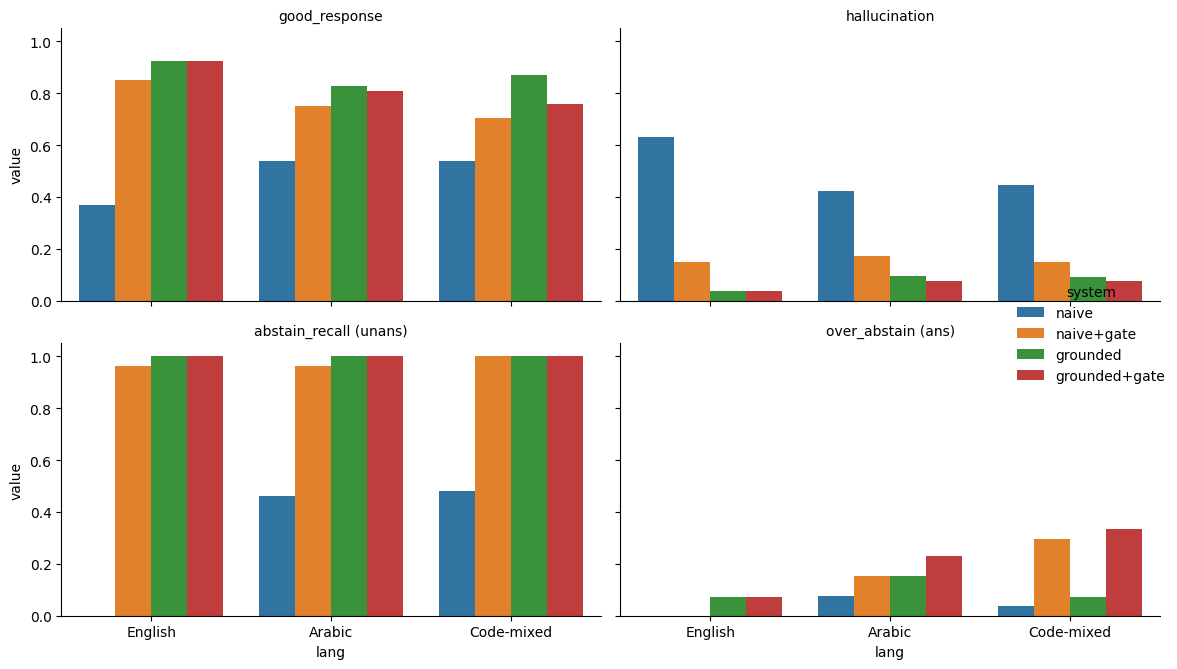

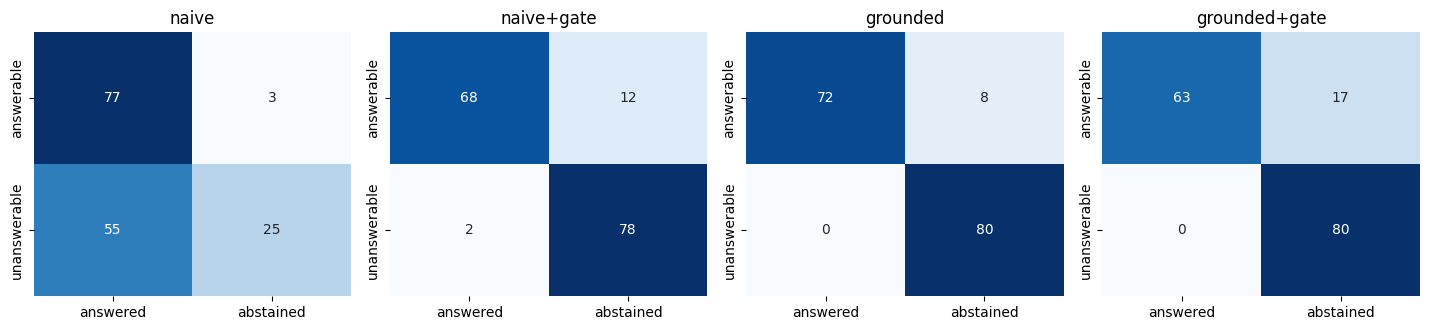

In [27]:
# ============================== 9c. FIGURES ==============================
ordr = ["English", "Arabic", "Code-mixed"]
plot_df = CI[CI.metric.isin(["good_response", "hallucination", "abstain_recall (unans)", "over_abstain (ans)"])]
g = sns.catplot(data=plot_df, x="lang", y="value", hue="system", col="metric", kind="bar", order=ordr, col_wrap=2, height=3.4, aspect=1.5, errorbar=None, sharey=True)
g.set_titles("{col_name}"); g.set(ylim=(0, 1.05)); plt.tight_layout(); plt.savefig(DIRS["figures"] / "metrics_by_language.png", dpi=200); plt.show()

systems = list(RES.keys()); fig, axes = plt.subplots(1, len(systems), figsize=(3.6 * len(systems), 3.4))
axes = np.atleast_1d(axes)
for ax, s in zip(axes, systems):
    d = RES[s]; cm = pd.crosstab(d.is_unans.map({False: "answerable", True: "unanswerable"}), d.abstained.map({False: "answered", True: "abstained"})).reindex(index=["answerable", "unanswerable"], columns=["answered", "abstained"], fill_value=0)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax); ax.set_title(s); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(DIRS["figures"] / "confusion_matrices.png", dpi=200); plt.show()

In [28]:
from pathlib import Path

figures_dir = Path(DIRS["figures"])

files_to_check = [
    "metrics_by_language.png",
    "confusion_matrices.png"
]

print("Figures folder:", figures_dir)

for filename in files_to_check:
    path = figures_dir / filename

    if path.exists():
        print(f"✅ SAVED: {filename}")
        print(f"   Size: {path.stat().st_size:,} bytes")
    else:
        print(f"❌ NOT FOUND: {filename}")

Figures folder: /content/drive/MyDrive/uae-gov-rag-hallucination/outputs/figures
✅ SAVED: metrics_by_language.png
   Size: 81,685 bytes
✅ SAVED: confusion_matrices.png
   Size: 52,169 bytes


## 10. Error analysis, judge validation, export

In [29]:
# ============================== 10. ERROR ANALYSIS ==============================
focus = "grounded" if "grounded" in RES else list(RES)[0]
d = RES[focus]
def show(df, title, n=6):
    print(f"\n### {title}  (n={len(df)})")
    if len(df): display(df[["question_id", "lang", "question_text", "answer", "faith", "corr_label", "judge_expl"]].head(n))
show(d[d.is_unans & ~d.abstained], f"[{focus}] FALSE ANSWERS on unanswerable questions (hallucination)")
show(d[~d.is_unans & d.abstained], f"[{focus}] OVER-ABSTENTIONS on answerable questions")
show(d[~d.abstained & d.faith.isin(["unsupported", "partially_supported"]) & ~d.is_unans], f"[{focus}] UNFAITHFUL answers on answerable questions")
# retrieval failure vs generation failure on answerable questions
a = d[~d.is_unans].copy(); a["retrieved_relevant"] = [any(x in set(r) for x in ids) for ids, r in zip(a.retrieved_ids, a.rel_ids)]
print("\nAnswerable questions: P(good | relevant passage retrieved) vs P(good | not retrieved)")
display(a.groupby(["lang", "retrieved_relevant"]).agg(n=("good", "size"), good=("good", "mean"), over_abstain=("abstained", "mean")).round(3))
for k, v in {"overall": OVERALL, "by_language": BYLANG, "ci": CI, "language_tests": TESTS, "system_tests": PAIRED, "retrieval": RET.groupby(["method", "lang"]).mean(numeric_only=True).round(3), "gate_auroc": GATE_AUC}.items():
    v.to_csv(DIRS["tables"] / f"{k}.csv", encoding="utf-8-sig")
with pd.ExcelWriter(DIRS["tables"] / "all_tables.xlsx") as xw:
    for k, v in {"overall": OVERALL, "by_language": BYLANG, "ci": CI, "language_tests": TESTS, "system_tests": PAIRED, "gate_auroc": GATE_AUC}.items(): v.to_excel(xw, sheet_name=k[:30])


### [grounded] FALSE ANSWERS on unanswerable questions (hallucination)  (n=0)

### [grounded] OVER-ABSTENTIONS on answerable questions  (n=8)


,question_id,lang,question_text,answer,faith,corr_label,judge_expl
12,Q0023,Arabic,ماذا يُقصد بضريبة القيمة المضافة؟,المعلومات غير متوفرة في المصادر المستدلة.,not_applicable,not_applicable,local: abstained
31,Q0050,Arabic,هل يجوز للفرد تنظيم حملة لجمع التبرعات لغرض خيري في الإمارات؟,لا يمكن تنفيذ أنشطة جمع التبرعات إلا بعد الحصول على تصريح من الجمعيات الخيرية المسجلة في دولة الإمارات.,not_applicable,not_applicable,local: abstained
36,Q0058,English,What is the procedure for reporting people who beg in the UAE?,The requested information is not available in the provided sources.,not_applicable,not_applicable,local: abstained
38,Q0061,English,Which federal authority is responsible for licensing charitable organisations in the UAE?,The provided sources do not contain information about the federal authority responsible for licensing charitable org...,not_applicable,not_applicable,local: abstained
39,Q0062,Arabic,أي سلطة اتحادية تتولى مسؤولية ترخيص المؤسسات الخيرية في الإمارات؟,المعلومات غير متوفرة في المصادر المقدمة.,not_applicable,not_applicable,local: abstained
64,Q0095,Arabic,هل تُشترط شهادة الفحص الطبي قبل الزواج لإتمام الزواج في الإمارات، بما في ذلك لغير المسلمين؟,نعم، تُعد شهادة الفحص الطبي قبل الزواج مطلوبة لجميع الراغبين في الزواج في دولة الإمارات، ولا يمكن إتمام أي عقد زواج ...,not_applicable,not_applicable,local: abstained



### [grounded] UNFAITHFUL answers on answerable questions  (n=12)


,question_id,lang,question_text,answer,faith,corr_label,judge_expl
5,Q0008,Arabic,ما المتطلبات اللازمة للاستفادة من خدمات المنشآت الصحية في دولة الإمارات؟,للولوج إلى خدمات المنشآت الصحية في دولة الإمارات، يتعين عليك تقديم بطاقة الهوية الإماراتية أو جواز السفر.,unsupported,correct,local NLI min-support=0.00
6,Q0010,English,Does the UAE government involve the public when developing health services or policies?,"Yes, the UAE Government engages people through consultations when designing health-related services or policies. You...",partially_supported,correct,local NLI min-support=0.00
7,Q0011,Arabic,هل تستشير حكومة الإمارات الجمهور عند تطوير الخدمات أو السياسات الصحية؟,نعم، تشرك حكومة دولة الإمارات الجمهور من خلال المشاورات عند تطوير الخدمات أو السياسات المتعلقة بالصحة، ويمكن العثور ...,unsupported,correct,local NLI min-support=0.22
8,Q0016,English,What should I do if a medical emergency occurs?,Call for the ambulance on 998 from anywhere in the UAE. An air ambulance may be sent for the patient if needed. For ...,partially_supported,correct,local NLI min-support=0.37
13,Q0024,Code-mixed,ما هي Value Added Tax (VAT)؟,فُرضت ضريبة القيمة المضافة (Value Added Tax) في دولة الإمارات في ١ يناير ٢٠١٨، وتبلغ نسبتها ٥ بالمئة. وستوفر ضريبة ا...,partially_supported,partially_correct,local NLI min-support=0.27
15,Q0027,Code-mixed,ما هي Certificate of VAT؟,Certificate of VAT هي شهادة تُصدر للشركات أو الأفراد لتمكينهم من المطالبة قانونًا بالإعفاءات من ضريبة القيمة المضافة...,unsupported,correct,local NLI min-support=0.14



Answerable questions: P(good | relevant passage retrieved) vs P(good | not retrieved)


n   good  over_abstain
lang       retrieved_relevant                         
Arabic     True                26  0.654         0.154
Code-mixed False                1  0.000         1.000
           True                26  0.769         0.038
English    False                1  0.000         1.000
           True                26  0.885         0.038

In [ ]:
# ============================== 11. EXPORT CONFIG + PROJECT FILES ==============================
(DIRS["reports"] / "run_config.json").write_text(json.dumps(dict(CFG=CFG, TAU=float(TAU), n_questions=len(questions), n_eval=len(eval_df), api_stats=dict(API_STATS)), indent=2, default=str))
(PROJECT_DIR / "requirements.txt").write_text("sentence-transformers\nrank_bm25\ngoogle-genai\nopenai\npandas\nnumpy\nscikit-learn\nscipy\nmatplotlib\nseaborn\ntqdm\nopenpyxl\n")
(PROJECT_DIR / ".env.example").write_text("GEMINI_API_KEY=your_key_from_aistudio.google.com/apikey\nGROQ_API_KEY=your_key_from_console.groq.com/keys\n")
(PROJECT_DIR / ".gitignore").write_text(".env\noutputs/cache/\n__pycache__/\n.ipynb_checkpoints/\n")
print("Saved. Folder contents:")
for p in sorted(PROJECT_DIR.rglob("*")):
    if p.is_file() and "cache" not in p.parts: print("  ", p.relative_to(PROJECT_DIR))

Completed